In [2]:
from pathlib import Path
import sys
import pandas as pd

# پیدا کردن ریشهٔ پروژه، چه از notebooks اجرا کنیم چه از ریشه
ROOT = Path.cwd()

if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from nhanes_analyzer import NhanesAnalyzer

# پسوند فایل‌های ارسالی تو کوچک است: .xpt
analyzer = NhanesAnalyzer(
    ROOT / "data" / "DEMO_L.xpt",
    ROOT / "data" / "BMX_L.xpt"
)

# هر شناسه باید نمایندهٔ فقط یک فرد باشد
assert analyzer.demo_df["SEQN"].is_unique
assert analyzer.bmx_df["SEQN"].is_unique

analyzer.merge_files()
analyzer.define_population(min_age=20)

adults = analyzer.analytical_population.copy()

# گمشدگی وزن را قبل از تعریف رویداد دودویی بررسی می‌کنیم
print("تعداد بزرگسالان پس از اتصال:", len(adults))
print("تعداد وزن‌های بدن گمشده:", adults["BMXWT"].isna().sum())

df = adults.dropna(
    subset=["BMXWT", "RIDAGEYR", "RIAGENDR", "WTMEC2YR"]
).copy()

df = df.loc[
    df["RIAGENDR"].isin([1, 2])
    & df["WTMEC2YR"].gt(0)
].copy()

print("تعداد افراد نمونهٔ نهایی:", len(df))

df[
    ["SEQN", "RIDAGEYR", "RIAGENDR", "BMXWT", "WTMEC2YR"]
].head()

تعداد بزرگسالان پس از اتصال: 6064
تعداد وزن‌های بدن گمشده: 81
تعداد افراد نمونهٔ نهایی: 5983


,SEQN,RIDAGEYR,RIAGENDR,BMXWT,WTMEC2YR
0,130378.0,43.0,1.0,86.9,54374.463898
1,130379.0,66.0,1.0,101.8,34084.721548
2,130380.0,44.0,2.0,69.4,81196.277992
5,130386.0,34.0,1.0,90.6,39988.452940
6,130387.0,68.0,2.0,103.5,20776.254850


In [3]:
# متغیرهای کمی
df["X_weight"] = df["BMXWT"]
df["Y_age"] = df["RIDAGEYR"]

# رویداد A: وزن بدن حداقل ۹۰ کیلوگرم
df["A"] = df["X_weight"] >= 90

# رویداد B: جنس ثبت‌شده مرد
df["B"] = df["RIAGENDR"] == 1

# متغیر تصادفی شاخص رویداد A:
# وقوع رویداد = ۱، عدم وقوع = ۰
df["I_A"] = df["A"].astype(int)

print("تعداد کل افراد:", len(df))
print("تعداد افراد با وزن حداقل ۹۰ کیلوگرم:", df["A"].sum())
print("تعداد مردان:", df["B"].sum())

df[
    ["X_weight", "Y_age", "RIAGENDR", "A", "B", "I_A"]
].head()

تعداد کل افراد: 5983
تعداد افراد با وزن حداقل ۹۰ کیلوگرم: 1939
تعداد مردان: 2688


,X_weight,Y_age,RIAGENDR,A,B,I_A
0,86.9,43.0,1.0,False,True,0
1,101.8,66.0,1.0,True,True,1
2,69.4,44.0,2.0,False,False,0
5,90.6,34.0,1.0,True,True,1
6,103.5,68.0,2.0,True,False,1


In [4]:
# تعداد کل افراد نمونهٔ نهایی
N = len(df)

# تعداد وقوع رویدادها
n_A = df["A"].sum()
n_B = df["B"].sum()

# علامت & یعنی هر دو شرط هم‌زمان برقرار باشند
n_AB = (df["A"] & df["B"]).sum()

# احتمال‌های تجربی بدون وزن‌دهی
p_A = n_A / N
p_B = n_B / N
p_AB = n_AB / N

probability_table = pd.DataFrame({
    "Event": ["A", "B", "A ∩ B"],
    "Count": [n_A, n_B, n_AB],
    "Probability": [p_A, p_B, p_AB],
    "Percent": [100 * p_A, 100 * p_B, 100 * p_AB]
})

probability_table.round(4)

,Event,Count,Probability,Percent
0,A,1939,0.3241,32.4085
1,B,2688,0.4493,44.9273
2,A ∩ B,1118,0.1869,18.6863


In [5]:
# ~ یعنی نقیض رویداد
# چون جنس را قبلاً به کدهای ۱ و ۲ محدود کردیم،
# ~B در نمونهٔ ما همان گروه زنان است.
n_not_B = (~df["B"]).sum()
n_A_not_B = (df["A"] & ~df["B"]).sum()

# احتمال وزن حداقل ۹۰، به شرط مرد یا زن بودن
p_A_given_B = n_AB / n_B
p_A_given_not_B = n_A_not_B / n_not_B

conditional_table = pd.DataFrame({
    "Group": ["Male", "Female"],
    "Group_size": [n_B, n_not_B],
    "Count_A": [n_AB, n_A_not_B],
    "P(A|Group)": [p_A_given_B, p_A_given_not_B],
    "Percent": [
        100 * p_A_given_B,
        100 * p_A_given_not_B
    ]
})

display(conditional_table.round(4))

# اختلاف دو احتمال بر حسب واحد درصد
difference_pp = 100 * (p_A_given_B - p_A_given_not_B)

print(f"Difference: {difference_pp:.2f} percentage points")

,Group,Group_size,Count_A,P(A|Group),Percent
0,Male,2688,1118,0.4159,41.5923
1,Female,3295,821,0.2492,24.9165


Difference: 16.68 percentage points


In [6]:
# احتمال مشترک در صورت استقلال
p_AB_if_independent = p_A * p_B

# تفاوت احتمال مشترک مشاهده‌شده با حاصل‌ضرب احتمال‌ها
independence_gap = p_AB - p_AB_if_independent

independence_table = pd.DataFrame({
    "Quantity": [
        "P(A and B)",
        "P(A) * P(B)",
        "P(A | B)",
        "P(A)"
    ],
    "Value": [
        p_AB,
        p_AB_if_independent,
        p_A_given_B,
        p_A
    ]
})

display(independence_table.round(4))

print(f"Joint probability gap: {independence_gap:.4f}")

,Quantity,Value
0,P(A and B),0.1869
1,P(A) * P(B),0.1456
2,P(A | B),0.4159
3,P(A),0.3241


Joint probability gap: 0.0413


In [7]:
# روش اول: قضیهٔ بیز
p_B_given_A_bayes = (p_A_given_B * p_B) / p_A

# روش دوم: محاسبهٔ مستقیم از تعدادها
p_B_given_A_direct = n_AB / n_A

bayes_table = pd.DataFrame({
    "Method": ["Bayes formula", "Direct count"],
    "P(B|A)": [
        p_B_given_A_bayes,
        p_B_given_A_direct
    ]
})

display(bayes_table.round(4))

# بررسی برابری دو روش با تحمل خطای محاسبات اعشاری
assert abs(p_B_given_A_bayes - p_B_given_A_direct) < 1e-12

print(f"P(B): {100 * p_B:.2f}%")
print(f"P(B|A): {100 * p_B_given_A_bayes:.2f}%")

,Method,P(B|A)
0,Bayes formula,0.5766
1,Direct count,0.5766


P(B): 44.93%
P(B|A): 57.66%


In [8]:
# پارامتر برنولی: احتمال وقوع رویداد A
p = p_A

# محاسبه با فرمول‌های برنولی
bernoulli_mean = p
bernoulli_variance = p * (1 - p)

# محاسبه مستقیم از توزیع تجربی صفر و یک‌ها
empirical_mean = df["I_A"].mean()
empirical_variance = df["I_A"].var(ddof=0)

bernoulli_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance"],
    "Bernoulli_formula": [
        bernoulli_mean,
        bernoulli_variance
    ],
    "Empirical_calculation": [
        empirical_mean,
        empirical_variance
    ]
})

display(bernoulli_table.round(6))

,Quantity,Bernoulli_formula,Empirical_calculation
0,Mean,0.324085,0.324085
1,Variance,0.219054,0.219054


In [9]:
# تعداد افراد هر گروه
group_size = 30

# احتمال موفقیت؛ موفقیت اینجا فقط یعنی رخ‌دادن رویداد A
p = p_A

# امید و واریانس مدل دوجمله‌ای
binomial_mean = group_size * p
binomial_variance = group_size * p * (1 - p)
binomial_std = binomial_variance ** 0.5

binomial_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance", "Standard deviation"],
    "Value": [
        binomial_mean,
        binomial_variance,
        binomial_std
    ]
})

display(binomial_table.round(4))

,Quantity,Value
0,Mean,9.7225
1,Variance,6.5716
2,Standard deviation,2.5635


In [10]:
import numpy as np

# ثابت‌بودن بذر باعث می‌شود اجرای دوباره، همان نتیجه را بدهد
rng = np.random.default_rng(1405)

repeats = 10_000
group_size = 30

# آرایهٔ صفر و یک: وضعیت رویداد A برای افراد نمونه
event_values = df["I_A"].to_numpy()

# محل ذخیرهٔ تعداد وقوع رویداد در هر زیرنمونه
counts = np.empty(repeats, dtype=int)

for i in range(repeats):
    subsample = rng.choice(
        event_values,
        size=group_size,
        replace=False
    )

    counts[i] = subsample.sum()

print("First 10 counts:", counts[:10])
print("Number of repetitions:", len(counts))

# واریانس دقیق شمارش در انتخاب بدون جایگذاری
N = len(event_values)
finite_population_correction = (N - group_size) / (N - 1)

hypergeometric_variance = (
    binomial_variance * finite_population_correction
)

comparison_table = pd.DataFrame({
    "Quantity": ["Mean", "Variance"],
    "Repeated_subsamples": [
        counts.mean(),
        counts.var(ddof=0)
    ],
    "Binomial_model": [
        binomial_mean,
        binomial_variance
    ],
    "Hypergeometric_model": [
        binomial_mean,
        hypergeometric_variance
    ]
})

display(comparison_table.round(4))

First 10 counts: [12  8 11 17 15  9  7 14 10 13]
Number of repetitions: 10000


,Quantity,Repeated_subsamples,Binomial_model,Hypergeometric_model
0,Mean,9.7560,9.7225,9.7225
1,Variance,6.4711,6.5716,6.5398


In [11]:
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom

# تعدادهای ممکن: از صفر تا ۳۰ نفر
k = np.arange(group_size + 1)

# احتمال تجربی هر شمارش در ۱۰٬۰۰۰ تکرار
empirical_probs = (
    np.bincount(counts, minlength=group_size + 1) / repeats
)

# احتمال‌های مدل دوجمله‌ای
binomial_probs = binom.pmf(k, n=group_size, p=p)

# احتمال‌های مدل دقیق فوق‌هندسی
N = len(event_values)
M = int(event_values.sum())

hypergeometric_probs = hypergeom.pmf(
    k,
    M=N,             # اندازهٔ کل مجموعه
    n=M,             # تعداد افراد دارای رویداد A
    N=group_size     # اندازهٔ زیرنمونه
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    k, empirical_probs,
    color="lightsteelblue",
    label="Repeated subsamples",
    alpha=0.8
)

ax.plot(
    k, binomial_probs,
    "o-", color="darkred",
    markersize=4,
    label="Binomial model"
)

ax.plot(
    k, hypergeometric_probs,
    "--", color="black",
    label="Hypergeometric model"
)

ax.set_xlabel("Number of people with weight >= 90 kg")
ax.set_ylabel("Probability")
ax.set_title("Counts in random subsamples of 30 adults")
ax.set_xticks(np.arange(0, group_size + 1, 2))
ax.legend()

fig.tight_layout()

# ذخیرهٔ شکل برای گزارش
figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "binomial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ModuleNotFoundError: No module named 'scipy'

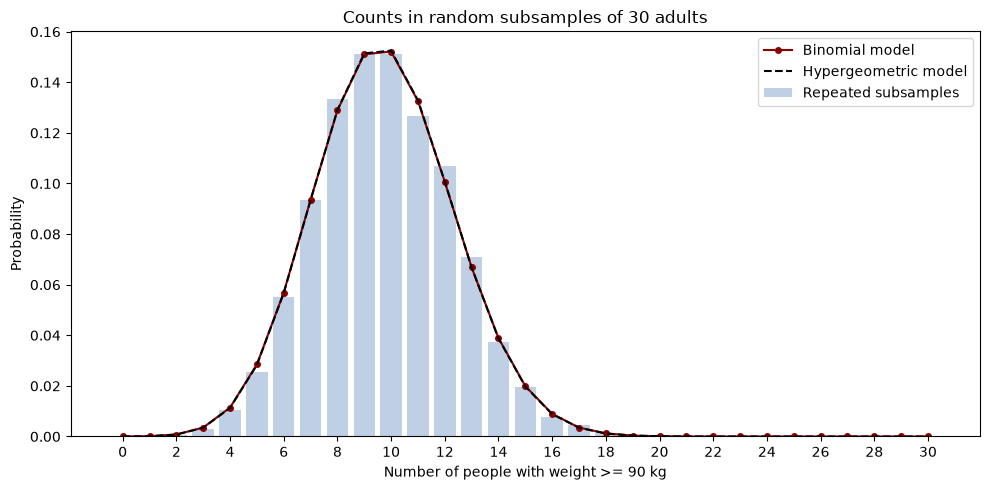

In [13]:
import matplotlib.pyplot as plt
from scipy.stats import binom, hypergeom

# تعدادهای ممکن: از صفر تا ۳۰ نفر
k = np.arange(group_size + 1)

# احتمال تجربی هر شمارش در ۱۰٬۰۰۰ تکرار
empirical_probs = (
    np.bincount(counts, minlength=group_size + 1) / repeats
)

# احتمال‌های مدل دوجمله‌ای
binomial_probs = binom.pmf(k, n=group_size, p=p)

# احتمال‌های مدل دقیق فوق‌هندسی
N = len(event_values)
M = int(event_values.sum())

hypergeometric_probs = hypergeom.pmf(
    k,
    M=N,             # اندازهٔ کل مجموعه
    n=M,             # تعداد افراد دارای رویداد A
    N=group_size     # اندازهٔ زیرنمونه
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    k, empirical_probs,
    color="lightsteelblue",
    label="Repeated subsamples",
    alpha=0.8
)

ax.plot(
    k, binomial_probs,
    "o-", color="darkred",
    markersize=4,
    label="Binomial model"
)

ax.plot(
    k, hypergeometric_probs,
    "--", color="black",
    label="Hypergeometric model"
)

ax.set_xlabel("Number of people with weight >= 90 kg")
ax.set_ylabel("Probability")
ax.set_title("Counts in random subsamples of 30 adults")
ax.set_xticks(np.arange(0, group_size + 1, 2))
ax.legend()

fig.tight_layout()

# ذخیرهٔ شکل برای گزارش
figure_dir = ROOT / "figures" / "phase2"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "binomial_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
